In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller,acf,pacf
from statsmodels.tsa.arima.model import ARIMA
import statsmodels.tsa.api as smt

In [3]:
pd.read_csv('Air Passengers.csv').head(),pd.read_csv('Air Passengers.csv').tail()

(     Month  #Passengers
 0  1949-01          112
 1  1949-02          118
 2  1949-03          132
 3  1949-04          129
 4  1949-05          121,
        Month  #Passengers
 139  1960-08          606
 140  1960-09          508
 141  1960-10          461
 142  1960-11          390
 143  1960-12          432)

In [4]:
pd.read_csv('Air Passengers.csv').info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Month        144 non-null    object
 1   #Passengers  144 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 2.4+ KB


In [5]:
air= pd.read_csv('Air Passengers.csv',parse_dates=True, index_col='Month')
air.head()

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [6]:
air.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   #Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


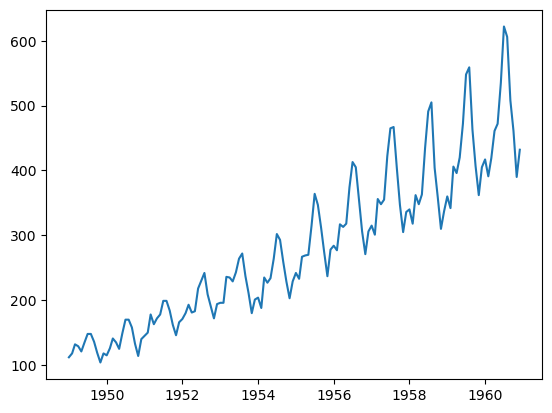

In [7]:
plt.plot(air)

<Axes: xlabel='Month'>

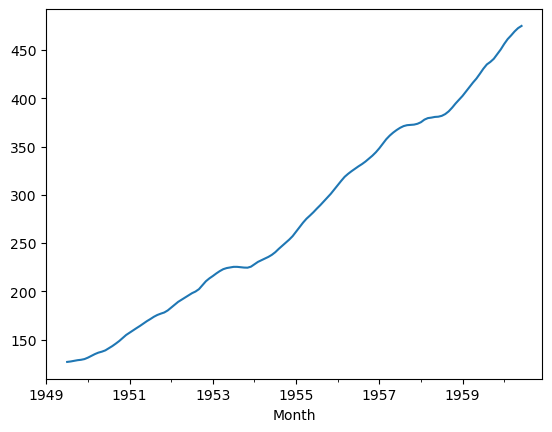

In [8]:
result= seasonal_decompose(air['#Passengers'],model='additive')
result.trend.plot()

<Axes: xlabel='Month'>

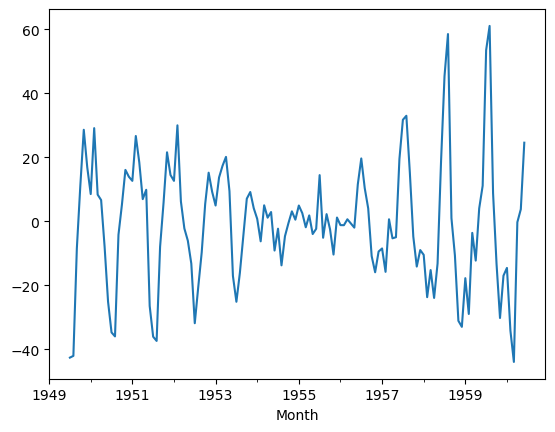

In [9]:
result.resid.plot()

<Axes: xlabel='Month'>

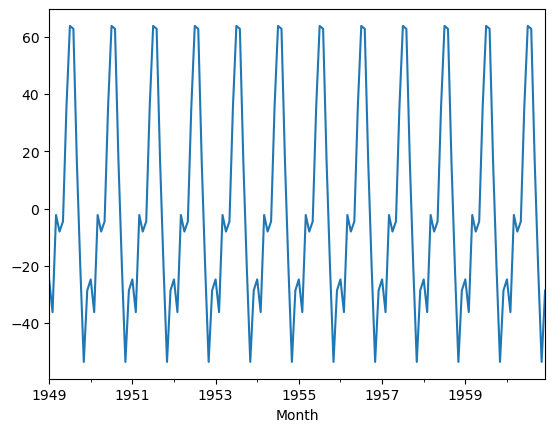

In [10]:
result.seasonal.plot()

## ARIMA

In [23]:
air= pd.read_csv('Air Passengers.csv',index_col='Month',parse_dates=True)

In [24]:
air.head()

,#Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


In [25]:
def test_stationarity(timeseries):

    #Calculate rolling mean and rolling standard deviation
    rolmean = timeseries.rolling(window = 12).mean()
    rolstd = timeseries.rolling(window = 12).std()

    original = plt.plot(timeseries, color = 'blue', label = 'Original')
    mean = plt.plot(rolmean, color = 'red', label = 'Rolling Mean')
    std = plt.plot(rolstd, color = 'green', label = 'Rolling Std')
    plt.legend(loc='best')


    print('Results of Dickey-Fuller Test :\n')
    df_test = adfuller(timeseries)
    my_output = pd.Series(df_test[0:4], index =['Test Statistic', 'p-value', '#Lags Used', 'Number of Observations Used'])
    for i,j in df_test[4].items():
        my_output['Critical Value (%s)'%i] =j
    print(my_output)

Results of Dickey-Fuller Test :

Test Statistic                   0.815369
p-value                          0.991880
#Lags Used                      13.000000
Number of Observations Used    130.000000
Critical Value (1%)             -3.481682
Critical Value (5%)             -2.884042
Critical Value (10%)            -2.578770
dtype: float64


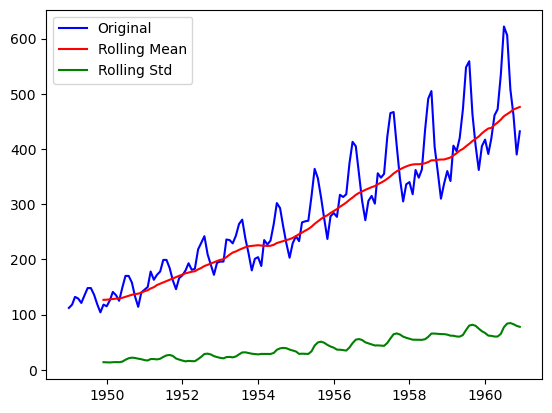

In [26]:
test_stationarity(air['#Passengers'])

### Differencing

In [27]:
air['Air_Diff']= air['#Passengers']-air['#Passengers'].shift(12)

In [28]:
air

,#Passengers,Air_Diff
Month,,
1949-01-01,112,NaN
1949-02-01,118,NaN
1949-03-01,132,NaN
1949-04-01,129,NaN
1949-05-01,121,NaN
...,...,...
1960-08-01,606,47.0
1960-09-01,508,45.0
1960-10-01,461,54.0


In [29]:
air.dropna(inplace=True)

In [30]:
air

,#Passengers,Air_Diff
Month,,
1950-01-01,115,3.0
1950-02-01,126,8.0
1950-03-01,141,9.0
1950-04-01,135,6.0
1950-05-01,125,4.0
...,...,...
1960-08-01,606,47.0
1960-09-01,508,45.0
1960-10-01,461,54.0


Results of Dickey-Fuller Test :

Test Statistic                  -3.383021
p-value                          0.011551
#Lags Used                       1.000000
Number of Observations Used    130.000000
Critical Value (1%)             -3.481682
Critical Value (5%)             -2.884042
Critical Value (10%)            -2.578770
dtype: float64


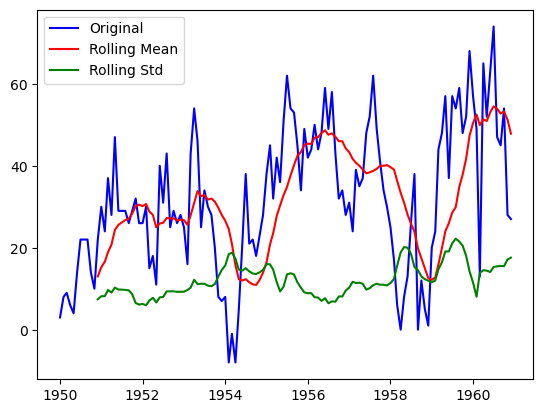

In [31]:
test_stationarity(air['Air_Diff'])

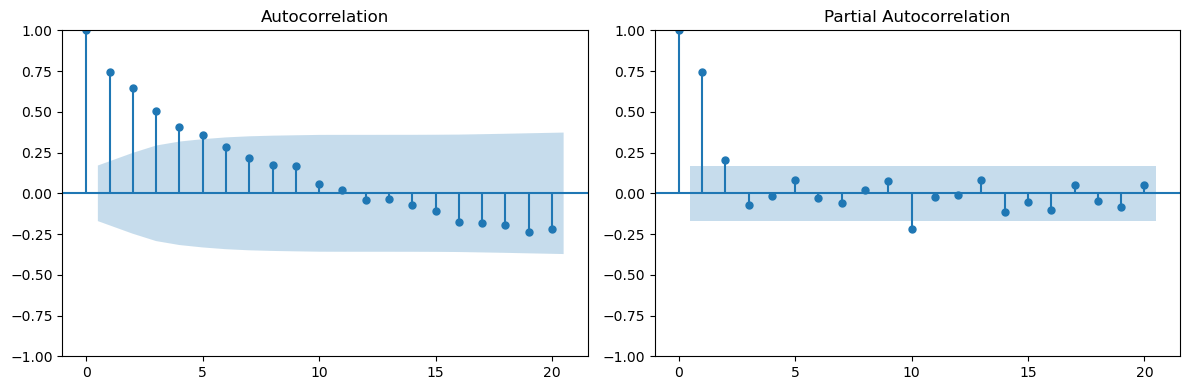

In [32]:
fig, axes = plt.subplots(1, 2)
fig.set_figwidth(12)
fig.set_figheight(4)
smt.graphics.plot_acf(air['Air_Diff'], lags=20, ax=axes[0])
smt.graphics.plot_pacf(air['Air_Diff'], lags=20, ax=axes[1])
plt.tight_layout()

In [58]:
import warnings
warnings.filterwarnings('ignore')
model = ARIMA(air['#Passengers'], order=(2,1,1))

In [59]:
air.columns

Index(['#Passengers', 'Air_Diff', 'predicted'], dtype='object')

In [60]:
air.head()

,#Passengers,Air_Diff,predicted
Month,,,
1950-01-01,115,3.0,0.000000
1950-02-01,126,8.0,115.035557
1950-03-01,141,9.0,128.711396
1950-04-01,135,6.0,143.355783
1950-05-01,125,4.0,131.155332


In [61]:
result= model.fit()
result.predict()

1950-01-01      0.000000
1950-02-01    115.044344
1950-03-01    129.412703
1950-04-01    143.960568
1950-05-01    127.816801
                 ...    
1960-08-01    614.729959
1960-09-01    553.314368
1960-10-01    447.076288
1960-11-01    445.884856
1960-12-01    382.661779
Freq: MS, Name: predicted_mean, Length: 132, dtype: float64

In [62]:
result.forecast(30)

1961-01-01    470.955734
1961-02-01    492.939198
1961-03-01    497.878187
1961-04-01    492.511339
1961-05-01    484.232927
1961-06-01    477.819447
1961-07-01    474.867722
1961-08-01    474.783561
1961-09-01    476.136465
1961-10-01    477.655100
1961-11-01    478.651307
1961-12-01    478.995874
1962-01-01    478.884534
1962-02-01    478.594286
1962-03-01    478.331820
1962-04-01    478.187264
1962-05-01    478.157874
1962-06-01    478.196535
1962-07-01    478.253142
1962-08-01    478.296035
1962-09-01    478.315168
1962-10-01    478.315068
1962-11-01    478.305593
1962-12-01    478.295294
1963-01-01    478.288686
1963-02-01    478.286510
1963-03-01    478.287369
1963-04-01    478.289371
1963-05-01    478.291138
1963-06-01    478.292087
Freq: MS, Name: predicted_mean, dtype: float64

In [63]:
air['predicted']=result.predict()

In [64]:
air.head()

,#Passengers,Air_Diff,predicted
Month,,,
1950-01-01,115,3.0,0.000000
1950-02-01,126,8.0,115.044344
1950-03-01,141,9.0,129.412703
1950-04-01,135,6.0,143.960568
1950-05-01,125,4.0,127.816801


In [65]:
forecast=result.forecast(20)
forecast

1961-01-01    470.955734
1961-02-01    492.939198
1961-03-01    497.878187
1961-04-01    492.511339
1961-05-01    484.232927
1961-06-01    477.819447
1961-07-01    474.867722
1961-08-01    474.783561
1961-09-01    476.136465
1961-10-01    477.655100
1961-11-01    478.651307
1961-12-01    478.995874
1962-01-01    478.884534
1962-02-01    478.594286
1962-03-01    478.331820
1962-04-01    478.187264
1962-05-01    478.157874
1962-06-01    478.196535
1962-07-01    478.253142
1962-08-01    478.296035
Freq: MS, Name: predicted_mean, dtype: float64

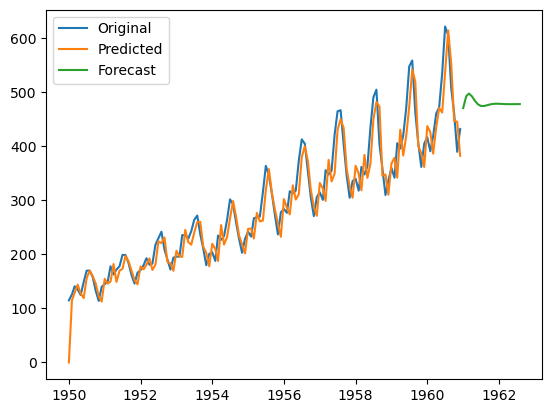

In [66]:
plt.plot(air['#Passengers'],label='Original')
plt.plot(air['predicted'],label='Predicted')
plt.plot(forecast,label='Forecast')
plt.legend()

In [67]:
from sklearn.metrics import mean_absolute_percentage_error,mean_squared_error,mean_absolute_error

In [68]:
mean_absolute_error(air['#Passengers'],air['predicted'])

24.861482233878693

In [69]:
mean_squared_error(air['#Passengers'],air['predicted'])

1006.8261343545519

In [70]:
mean_absolute_percentage_error(air['#Passengers'],air['predicted'])*100

8.783383162671573

#### SARIMAX

In [71]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
Model= SARIMAX(air['#Passengers'],order=(1,1,1),seasonal_order=(0,1,0,12))
results1=Model.fit()
sar_pred= results1.predict()

In [73]:
sar_fore= results1.forecast(30)
sar_fore

1961-01-01    444.166467
1961-02-01    418.110393
1961-03-01    446.129281
1961-04-01    488.122919
1961-05-01    499.125062
1961-06-01    562.124340
1961-07-01    649.124583
1961-08-01    633.124501
1961-09-01    535.124529
1961-10-01    488.124520
1961-11-01    417.124523
1961-12-01    459.124522
1962-01-01    471.290989
1962-02-01    445.234915
1962-03-01    473.253803
1962-04-01    515.247441
1962-05-01    526.249584
1962-06-01    589.248862
1962-07-01    676.249105
1962-08-01    660.249023
1962-09-01    562.249051
1962-10-01    515.249042
1962-11-01    444.249045
1962-12-01    486.249044
1963-01-01    498.415511
1963-02-01    472.359437
1963-03-01    500.378325
1963-04-01    542.371963
1963-05-01    553.374106
1963-06-01    616.373384
Freq: MS, Name: predicted_mean, dtype: float64

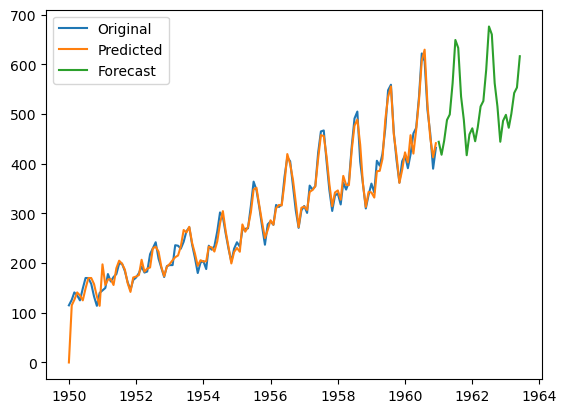

In [74]:
plt.plot(air['#Passengers'],label='Original')
plt.plot(sar_pred,label='Predicted')
plt.plot(sar_fore,label='Forecast')
plt.legend()

In [20]:
adfuller(air['#Passengers'])

(np.float64(0.8153688792060597),
 np.float64(0.9918802434376411),
 13,
 130,
 {'1%': np.float64(-3.4816817173418295),
  '5%': np.float64(-2.8840418343195267),
  '10%': np.float64(-2.578770059171598)},
 np.float64(996.692930839019))